# Deteksi Keramaian Ruang Lab Berbasis Audio
### Klasifikasi *Berisik* vs *Tidak Berisik* dengan Librosa + Machine Learning (CRISP-DM)

Notebook ini mengikuti tahapan **CRISP-DM** dari *Business Understanding* hingga *Deployment*:

| No | Tahap | Isi |
|---|---|---|
| 1 | Business Understanding | Masalah, tujuan, kriteria keberhasilan |
| 2 | Data Understanding | Jumlah data, durasi, sample rate, contoh sinyal & spektrogram |
| 3 | Data Preparation | Resample 16 kHz → chunk 5 detik → buang hening → ekstraksi fitur → agregasi (32 fitur) → split per file |
| 4 | Modeling | 3 metode: **Random Forest**, **SVM (RBF)**, **K-Nearest Neighbors**, dengan tuning hyperparameter |
| 5 | Evaluation | Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrix, pemilihan model terbaik |
| 6 | Deployment | Simpan model terbaik → dipakai `deteksi_lab.py` untuk memutar *"sssttt… jangan ramai"* |

**Struktur folder yang dibutuhkan:**
```
deteksi-keramaian-lab/
├── 01_klasifikasi_keramaian_lab.ipynb   <- notebook ini
├── fitur_audio.py                        <- fungsi pipeline (dipakai notebook & sistem)
├── deteksi_lab.py                        <- sistem real-time di lab
├── data/
│   ├── berisik/        <- 100 file audio berisik
│   └── non_berisik/    <- 100 file audio tidak berisik
├── model/   hasil/   suara/
```

## 0. Persiapan
Instal library (cukup sekali): `pip install -r requirements.txt`

In [1]:
import os, glob, time, platform, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import joblib
import sklearn

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)

import fitur_audio as fa   # modul pipeline bersama (lihat fitur_audio.py)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

# ---------------- Konfigurasi ----------------
DATA_DIR = "data"
KELAS = {"berisik": 1, "non_berisik": 0}        # nama subfolder -> label (sesuaikan bila beda)
NAMA_LABEL = {1: "Berisik", 0: "Tidak berisik"}
EKSTENSI = (".wav", ".mp3", ".flac", ".ogg", ".m4a")
RANDOM_STATE = 42
UKURAN_UJI = 0.2           # 80% latih, 20% uji (per FILE)
AUGMENTASI = False          # True = tambah data latih dengan noise & pitch shift (tips 2 modul)

os.makedirs("model", exist_ok=True)
os.makedirs("hasil", exist_ok=True)
print("librosa", librosa.__version__, "| scikit-learn", sklearn.__version__)
print("Konfigurasi pipeline:", {k: v for k, v in fa.konfigurasi().items() if k != "nama_fitur"})

librosa 1.0.0 | scikit-learn 1.9.0
Konfigurasi pipeline: {'sr': 16000, 'durasi_chunk': 5.0, 'frame_length': 2048, 'hop_length': 512, 'n_mfcc': 13, 'ambang_hening_db': -60.0}


---
## 1. Business Understanding

### 1.1 Latar belakang
Laboratorium komputer adalah ruang belajar yang membutuhkan suasana kondusif. Saat ramai
(banyak mahasiswa berbicara bersamaan), konsentrasi terganggu dan asisten/dosen tidak selalu
ada untuk menegur. Dibutuhkan sistem yang **mendengarkan suasana lab secara otomatis** dan
**memberi teguran suara** *"sssttt… jangan ramai"* ketika lab terdeteksi berisik.

### 1.2 Tujuan bisnis
1. Mengurangi kebisingan di lab tanpa harus diawasi terus-menerus oleh manusia.
2. Teguran bersifat otomatis, konsisten, dan tidak mengganggu saat lab memang tenang.

### 1.3 Tujuan data mining
Membangun model klasifikasi biner dari rekaman audio:
- **Label 1 – Berisik**: banyak orang berbicara / beraktivitas.
- **Label 0 – Tidak berisik**: sepi atau hanya suara latar (AC, kipas, ketikan keyboard).

Fitur yang dipakai (sesuai modul): **RMS** (energi), **Spectral Centroid** (pusat spektrum),
**Zero Crossing Rate** (lintas nol), dan **13 MFCC** (timbre/suara manusia), diagregasi
menjadi *mean* dan *std*. Tiga metode dibandingkan: **Random Forest, SVM, KNN**.

### 1.4 Kriteria keberhasilan
| Kriteria | Target | Alasan |
|---|---|---|
| F1-score (macro) pada data uji | ≥ 0,90 | Ukuran seimbang antara dua kelas |
| Precision kelas *Berisik* | ≥ 0,90 | Teguran palsu saat lab tenang akan mengganggu dan membuat sistem tidak dipercaya |
| Recall kelas *Berisik* | ≥ 0,85 | Sebagian besar keramaian harus tertangkap |
| Waktu prediksi per jendela 5 detik | < 1 detik | Supaya bisa berjalan real-time di PC lab |

### 1.5 Batasan dan asumsi
- Data: **100 rekaman berisik dan 100 rekaman tidak berisik**.
- Sistem dijalankan di PC/laptop lab dengan mikrofon dan speaker.
- Volume rekaman sangat dipengaruhi mikrofon dan jaraknya. Idealnya data latih direkam
  **dengan mikrofon yang sama dan di lab yang sama** dengan tempat sistem dipasang.

---
## 2. Data Understanding
### 2.1 Inventaris file

In [2]:
baris = []
for folder, label in KELAS.items():
    for path in sorted(glob.glob(os.path.join(DATA_DIR, folder, "*"))):
        if path.lower().endswith(EKSTENSI):
            baris.append({"path": path, "file": os.path.basename(path),
                          "kelas": folder, "label": label})
df_file = pd.DataFrame(baris)
assert len(df_file) > 0, f"Tidak ada file audio di {DATA_DIR}/{list(KELAS)}"
df_file["file_id"] = np.arange(len(df_file))
print("Total file:", len(df_file))
print("Format file:", dict(df_file["path"].str.lower().str.rsplit(".", n=1).str[-1].value_counts()))
df_file["kelas"].value_counts().to_frame("jumlah_file")

Total file: 200
Format file: {'mp3': np.int64(200)}


,jumlah_file
kelas,
berisik,100
non_berisik,100


**Cek pembacaan MP3.** librosa membaca MP3 lewat `soundfile` (libsndfile ≥ 1.1, sudah termasuk di
`soundfile` ≥ 0.12). Jika sel di bawah gagal, jalankan `pip install -U soundfile`, atau instal
**ffmpeg** sebagai cadangan.

In [3]:
contoh = df_file.iloc[0]["path"]
try:
    y_cek, sr_cek = librosa.load(contoh, sr=None, mono=True)
    print(f"OK: {os.path.basename(contoh)} terbaca, {sr_cek} Hz, {len(y_cek) / sr_cek:.1f} detik")
except Exception as e:
    raise RuntimeError(f"Gagal membaca {contoh}: {e}\n"
                       "Solusi: pip install -U soundfile  (atau instal ffmpeg)") from e

OK: 24-003 berisik (1).mp3 terbaca, 44100 Hz, 30.0 detik


### 2.2 Durasi, sample rate, dan tingkat kenyaringan tiap file

In [4]:
def sample_rate_asli(path):
    try:
        return librosa.get_samplerate(path)          # cepat, membaca header saja
    except Exception:
        return librosa.load(path, sr=None, duration=1.0)[1]   # cadangan untuk MP3

info = []
for r in df_file.itertuples():
    try:
        sr_asli = sample_rate_asli(r.path)
        y = fa.muat_audio(r.path)                       # mono, 16 kHz
        rms = librosa.feature.rms(y=y)[0]
        info.append({"file_id": r.file_id, "sr_asli": sr_asli,
                     "durasi_detik": len(y) / fa.SR,
                     "rms_db_rata2": 20 * np.log10(np.mean(rms) + 1e-10),
                     "persen_hening": 100 * np.mean(20 * np.log10(rms + 1e-10) < fa.AMBANG_HENING_DB),
                     "ok": True})
    except Exception as e:
        print("Gagal dibaca:", r.path, "->", e)
        info.append({"file_id": r.file_id, "ok": False})

df_file = df_file.merge(pd.DataFrame(info), on="file_id")
rusak = df_file[~df_file["ok"]]
print("File rusak/tidak terbaca:", len(rusak))
df_file = df_file[df_file["ok"]].reset_index(drop=True)

print("\nSample rate asli yang ditemukan:", sorted(df_file["sr_asli"].unique()))
df_file.groupby("kelas")[["durasi_detik", "rms_db_rata2", "persen_hening"]].describe().T.round(2)

File rusak/tidak terbaca: 0

Sample rate asli yang ditemukan: [np.int64(16000), np.int64(44100), np.int64(48000)]


kelas                berisik  non_berisik
durasi_detik  count   100.00       100.00
              mean     31.25        30.67
              std       3.41         1.47
              min      29.85        29.91
              25%      30.00        30.00
              50%      30.19        30.22
              75%      30.90        30.54
              max      48.14        38.46
rms_db_rata2  count   100.00       100.00
              mean    -23.39       -34.98
              std       6.99         9.50
              min     -40.14       -62.66
              25%     -27.78       -40.19
              50%     -22.13       -34.12
              75%     -18.62       -29.04
              max     -10.82       -15.64
persen_hening count   100.00       100.00
              mean      0.70         6.32
              std       2.22        15.27
              min       0.00         0.00
              25%       0.00         0.00
              50%       0.00         0.11
              75%       0.31         1.73
              max      11.90        76.46

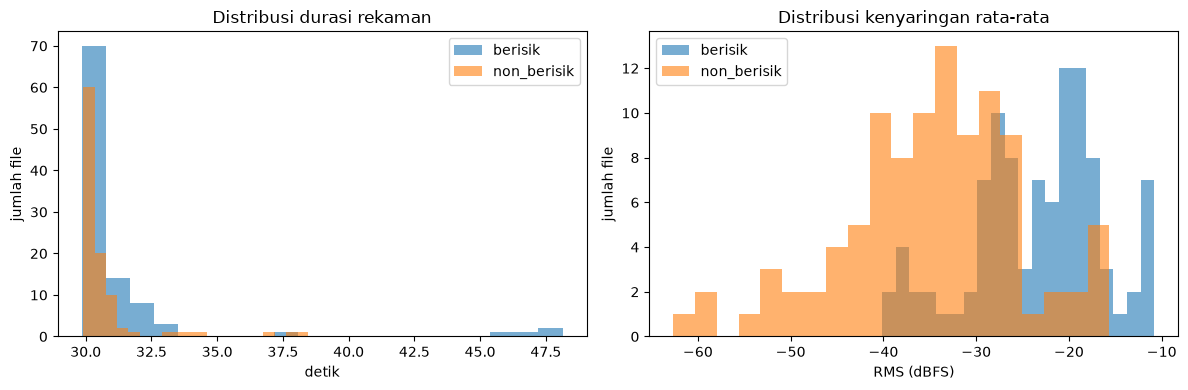

Perkiraan jumlah chunk 5 detik per kelas:
kelas
berisik        602
non_berisik    592
Name: chunk, dtype: int64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for folder in KELAS:
    d = df_file[df_file["kelas"] == folder]
    ax[0].hist(d["durasi_detik"], bins=20, alpha=0.6, label=folder)
    ax[1].hist(d["rms_db_rata2"], bins=20, alpha=0.6, label=folder)
ax[0].set(title="Distribusi durasi rekaman", xlabel="detik", ylabel="jumlah file")
ax[1].set(title="Distribusi kenyaringan rata-rata", xlabel="RMS (dBFS)", ylabel="jumlah file")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig("hasil/01_distribusi_durasi_rms.png"); plt.show()

print("Perkiraan jumlah chunk 5 detik per kelas:")
print((df_file.assign(chunk=np.maximum(1, df_file["durasi_detik"] // fa.DURASI_CHUNK))
       .groupby("kelas")["chunk"].sum().astype(int)))

### 2.3 Contoh sinyal dan spektrogram tiap kelas

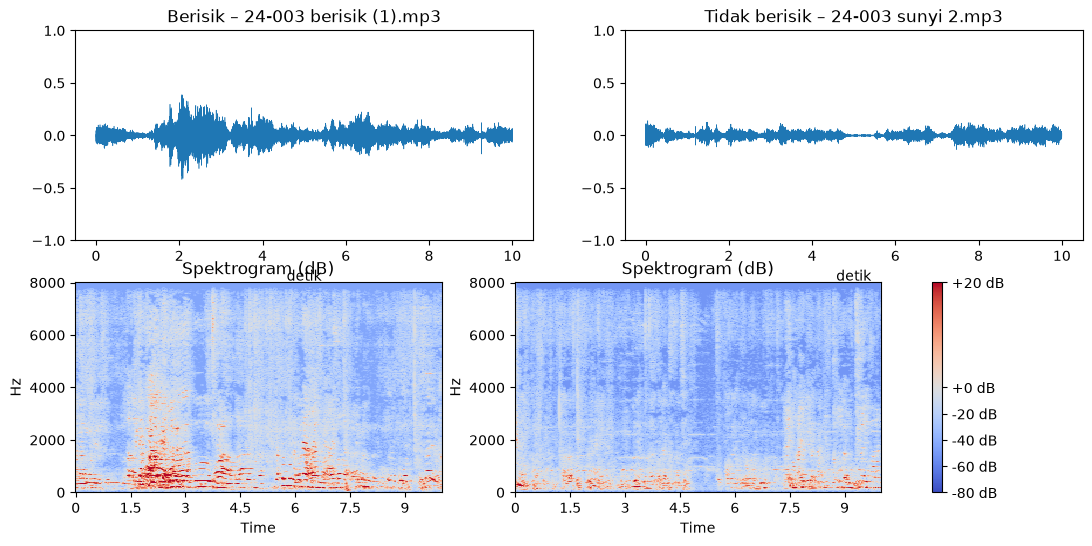

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for i, (folder, label) in enumerate(KELAS.items()):
    contoh = df_file[df_file["kelas"] == folder].iloc[0]
    y = fa.muat_audio(contoh["path"])[: int(10 * fa.SR)]          # 10 detik pertama
    t = np.arange(len(y)) / fa.SR
    ax[0, i].plot(t, y, lw=0.4)
    ax[0, i].set(title=f"{NAMA_LABEL[label]} – {contoh['file']}", xlabel="detik", ylim=(-1, 1))
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=fa.FRAME_LENGTH,
                                                     hop_length=fa.HOP_LENGTH)), ref=1.0)
    img = librosa.display.specshow(S, sr=fa.SR, hop_length=fa.HOP_LENGTH,
                                   x_axis="time", y_axis="hz", ax=ax[1, i], vmin=-80, vmax=20)
    ax[1, i].set(title="Spektrogram (dB)")
fig.colorbar(img, ax=ax[1, :], format="%+2.0f dB")
plt.savefig("hasil/02_contoh_sinyal_spektrogram.png", bbox_inches="tight"); plt.show()

**Yang perlu diperhatikan dari Data Understanding:**
- Jika sample rate berbeda-beda, semuanya akan diseragamkan menjadi 16 kHz di tahap persiapan.
- Durasi yang berbeda-beda adalah alasan perlunya *chunking* dan *agregasi* fitur.
- Jika distribusi RMS kedua kelas sangat terpisah, model akan mudah membedakan.
  Jika tumpang tindih, fitur MFCC/centroid (karakter suara manusia) menjadi penting.
- Kolom `persen_hening` yang tinggi menunjukkan rekaman banyak jeda hening (tips 1 modul).

---
## 3. Data Preparation

Langkah-langkah (sesuai pipeline modul):
1. **Resample** semua audio ke 16 kHz, mono.
2. **Chunking**: potong rekaman menjadi potongan 5 detik (sisa ≥ 2 detik tetap dipakai). Panjang
   5 detik juga sama dengan jendela yang dipakai sistem real-time di lab.
3. **Buang hening**: frame dengan energi < −60 dBFS tidak ikut dihitung.
4. **Ekstraksi fitur per frame**: RMS, Spectral Centroid, ZCR, 13 MFCC.
5. **Agregasi** mean & std → **32 fitur** per chunk
   (2 RMS + 2 centroid + 2 ZCR + 13 mean MFCC + 13 std MFCC).

> Catatan: contoh kode di modul memakai data dummy `np.random.rand(100, 40)`. Angka 40 itu
> tidak sesuai dengan fungsi `extract_features`, yang sebenarnya menghasilkan **32 fitur**.
> Notebook ini memakai fitur asli dari file audio.

### 3.1 Split data PER FILE (sebelum chunking)
Split dilakukan terhadap **file asli**, bukan terhadap chunk. Jika chunk dari satu rekaman
tersebar di data latih dan data uji, model "sudah pernah mendengar" rekaman uji sehingga
hasil evaluasi menjadi terlalu optimistis (*data leakage*).

In [7]:
file_latih, file_uji = train_test_split(df_file, test_size=UKURAN_UJI,
                                        stratify=df_file["label"], random_state=RANDOM_STATE)
print("File latih:", len(file_latih), dict(file_latih["kelas"].value_counts()))
print("File uji  :", len(file_uji), dict(file_uji["kelas"].value_counts()))
assert set(file_latih["file_id"]).isdisjoint(set(file_uji["file_id"]))

File latih: 160 {'non_berisik': np.int64(80), 'berisik': np.int64(80)}
File uji  : 40 {'non_berisik': np.int64(20), 'berisik': np.int64(20)}


### 3.2 Ekstraksi & agregasi fitur
Augmentasi (tips 2 modul) **hanya** diterapkan pada data latih agar data uji tetap mewakili
rekaman asli. Defaultnya mati (`AUGMENTASI = False`) karena chunking sudah memperbanyak data;
aktifkan jika hasil evaluasi kurang baik.

In [8]:
rng = np.random.default_rng(RANDOM_STATE)

def augmentasi(seg):
    # Menghasilkan 2 variasi: tambah noise (SNR 20 dB) dan pitch shift +/-1 semitone.
    daya = np.mean(seg ** 2) + 1e-12
    noise = rng.normal(0, np.sqrt(daya / 10 ** (20 / 10)), len(seg)).astype(np.float32)
    geser = librosa.effects.pitch_shift(seg, sr=fa.SR, n_steps=rng.choice([-1, 1]))
    return [seg + noise, geser]

def proses(df_part, augment=False):
    X, y, grup, meta = [], [], [], []
    for r in df_part.itertuples():
        sinyal = fa.muat_audio(r.path)
        for k, seg in enumerate(fa.potong_chunk(sinyal)):
            variasi = [("asli", seg)]
            if augment:
                variasi += [(f"aug{j}", s) for j, s in enumerate(augmentasi(seg))]
            for jenis, s in variasi:
                X.append(fa.ekstrak_fitur(s))
                y.append(r.label); grup.append(r.file_id)
                meta.append({"file_id": r.file_id, "file": r.file, "chunk": k, "jenis": jenis})
    return np.array(X), np.array(y), np.array(grup), pd.DataFrame(meta)

t0 = time.time()
X_train, y_train, g_train, meta_train = proses(file_latih, augment=AUGMENTASI)
X_test,  y_test,  g_test,  meta_test  = proses(file_uji,   augment=False)
print(f"Selesai dalam {time.time() - t0:.1f} detik")
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Chunk latih per label:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Chunk uji per label  :", dict(zip(*np.unique(y_test,  return_counts=True))))
assert X_train.shape[1] == len(fa.NAMA_FITUR) == 32

Selesai dalam 62.4 detik
X_train: (992, 32) | X_test: (242, 32)
Chunk latih per label: {np.int64(0): np.int64(490), np.int64(1): np.int64(502)}
Chunk uji per label  : {np.int64(0): np.int64(120), np.int64(1): np.int64(122)}


In [9]:
df_fitur_train = pd.concat([meta_train, pd.DataFrame(X_train, columns=fa.NAMA_FITUR)], axis=1)
df_fitur_train["label"] = y_train
df_fitur_test = pd.concat([meta_test, pd.DataFrame(X_test, columns=fa.NAMA_FITUR)], axis=1)
df_fitur_test["label"] = y_test
df_fitur_train.to_csv("hasil/fitur_latih.csv", index=False)
df_fitur_test.to_csv("hasil/fitur_uji.csv", index=False)

print("Nilai kosong (NaN):", int(np.isnan(X_train).sum() + np.isnan(X_test).sum()))
df_fitur_train.head()

Nilai kosong (NaN): 0


,file_id,file,chunk,jenis,rms_mean,rms_std,centroid_mean,centroid_std,zcr_mean,zcr_std,...,mfcc5_std,mfcc6_std,mfcc7_std,mfcc8_std,mfcc9_std,mfcc10_std,mfcc11_std,mfcc12_std,mfcc13_std,label
0,154,24-118 non-berisik 3.mp3,0,asli,0.101791,0.049812,1406.878296,310.734711,0.108072,0.031136,...,16.998711,14.469831,12.765174,9.947416,10.361632,11.453774,11.751492,8.054655,7.601727,0
1,154,24-118 non-berisik 3.mp3,1,asli,0.159633,0.063492,1247.270264,380.707214,0.087741,0.033233,...,13.016274,15.596920,9.504227,8.645950,11.320197,9.861107,9.342996,8.577763,9.583998,0
2,154,24-118 non-berisik 3.mp3,2,asli,0.144821,0.061384,1160.478149,173.071121,0.083900,0.016196,...,12.518016,14.299164,9.390962,11.260153,9.776818,9.574265,10.468018,8.664574,9.673686,0
3,154,24-118 non-berisik 3.mp3,3,asli,0.124296,0.063695,1083.668335,379.037079,0.074642,0.028720,...,14.404828,12.555820,13.784927,15.598536,10.548264,9.050102,7.977363,9.869954,7.234825,0
4,154,24-118 non-berisik 3.mp3,4,asli,0.157764,0.059005,1177.603760,214.824066,0.086295,0.020444,...,14.589911,14.761353,14.334096,14.209726,17.196138,15.665594,12.513109,10.072155,10.597515,0


### 3.3 Eksplorasi fitur hasil agregasi

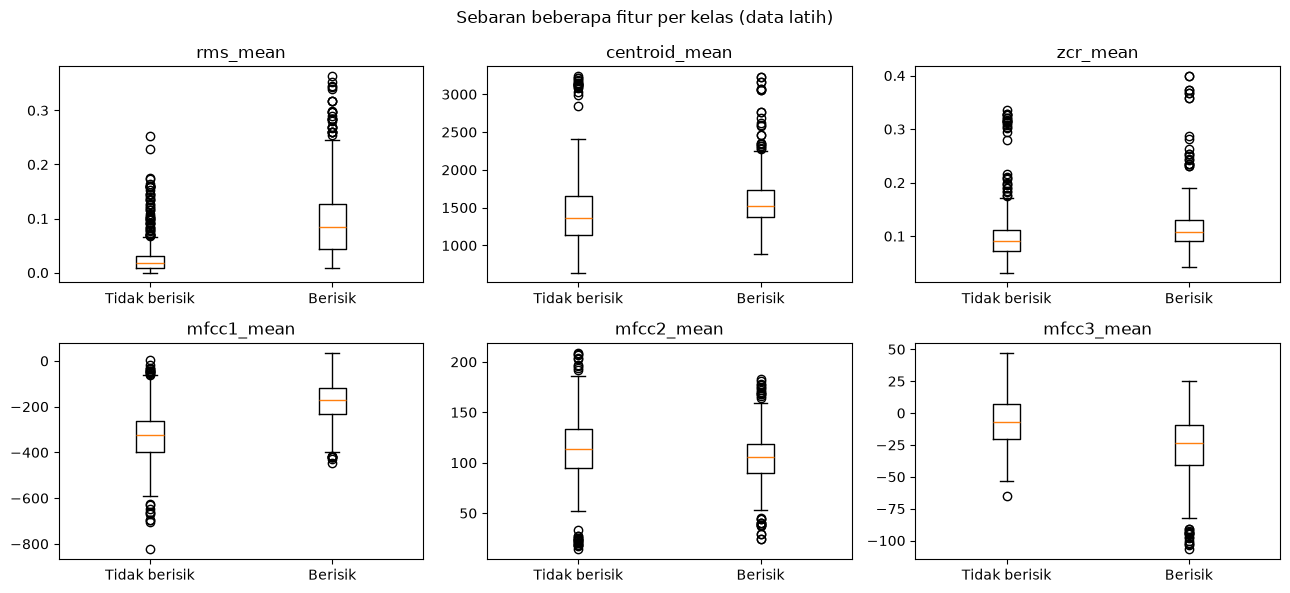

,rms_mean,rms_std,centroid_mean,centroid_std,zcr_mean,zcr_std
label,,,,,,
Tidak berisik,0.0289,0.0163,1447.359009,363.907013,0.1012,0.0362
Berisik,0.0952,0.0434,1574.659912,326.263397,0.1181,0.0363


In [10]:
fitur_lihat = ["rms_mean", "centroid_mean", "zcr_mean", "mfcc1_mean", "mfcc2_mean", "mfcc3_mean"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, f in zip(ax.ravel(), fitur_lihat):
    data = [df_fitur_train.loc[df_fitur_train["label"] == l, f] for l in (0, 1)]
    a.boxplot(data)
    a.set_xticks([1, 2], [NAMA_LABEL[0], NAMA_LABEL[1]])
    a.set_title(f)
plt.suptitle("Sebaran beberapa fitur per kelas (data latih)")
plt.tight_layout(); plt.savefig("hasil/03_boxplot_fitur.png"); plt.show()

df_fitur_train.groupby("label")[fa.NAMA_FITUR[:6]].mean().rename(index=NAMA_LABEL).round(4)

---
## 4. Modeling

Tiga metode yang dibandingkan:

| Metode | Cara kerja singkat | Perlu scaling? |
|---|---|---|
| **Random Forest** | Kumpulan banyak pohon keputusan, hasil voting. Metode utama di modul; tahan non-linearitas dan memberi *feature importance*. | Tidak |
| **SVM (kernel RBF)** | Mencari batas pemisah dengan margin terbesar di ruang berdimensi tinggi; kuat untuk data kecil-menengah. | Ya |
| **K-Nearest Neighbors** | Menentukan kelas berdasarkan *k* tetangga terdekat. Sederhana, sebagai pembanding (baseline). | Ya |

Fitur memiliki skala yang sangat berbeda (centroid ribuan Hz, RMS < 1), sehingga SVM dan KNN
dibungkus `Pipeline` dengan `StandardScaler`. Scaler ikut dilatih di dalam *cross-validation*
sehingga tidak bocor ke data validasi.

**Tuning hyperparameter**: `GridSearchCV` dengan `StratifiedGroupKFold` (5 fold). *Group* = file asli,
jadi chunk dari satu rekaman tidak pernah terbelah antara fold latih dan validasi.
Metrik pemilihan: **F1-macro**.

In [11]:
model_dan_grid = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [100, 300], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2]},
    ),
    "SVM (RBF)": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    ),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"]},
    ),
}
# Ingin menambah metode lain? cukup tambahkan satu entri, misalnya:
# from sklearn.ensemble import GradientBoostingClassifier
# model_dan_grid["Gradient Boosting"] = (GradientBoostingClassifier(random_state=RANDOM_STATE),
#                                        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1]})

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
hasil_tuning, model_terlatih = [], {}

for nama, (estimator, grid) in model_dan_grid.items():
    t0 = time.time()
    gs = GridSearchCV(estimator, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train, groups=g_train)
    model_terlatih[nama] = gs.best_estimator_
    hasil_tuning.append({"Metode": nama, "F1 CV (mean)": gs.best_score_,
                         "F1 CV (std)": gs.cv_results_["std_test_score"][gs.best_index_],
                         "Waktu tuning (s)": time.time() - t0,
                         "Parameter terbaik": gs.best_params_})
    print(f"{nama:15s} | F1 CV = {gs.best_score_:.4f} | {gs.best_params_}")

df_tuning = pd.DataFrame(hasil_tuning)
df_tuning.round(4)

Random Forest   | F1 CV = 0.7900 | {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 300}
SVM (RBF)       | F1 CV = 0.8173 | {'clf__C': 10, 'clf__gamma': 'scale'}
KNN             | F1 CV = 0.8141 | {'clf__n_neighbors': 5, 'clf__weights': 'uniform'}


,Metode,F1 CV (mean),F1 CV (std),Waktu tuning (s),Parameter terbaik
0,Random Forest,0.7900,0.0207,38.5893,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es..."
1,SVM (RBF),0.8173,0.0330,4.2215,"{'clf__C': 10, 'clf__gamma': 'scale'}"
2,KNN,0.8141,0.0276,0.6758,"{'clf__n_neighbors': 5, 'clf__weights': 'unifo..."


---
## 5. Evaluation

Model dievaluasi pada **data uji (20% file yang tidak pernah dilihat saat training/tuning)**
dalam dua level:
- **Level chunk**: tiap potongan 5 detik dinilai sendiri, sama seperti cara kerja sistem di lab.
- **Level file**: label file = mayoritas prediksi chunk-nya (pelengkap).

In [12]:
evaluasi, prediksi = [], {}
for nama, model in model_terlatih.items():
    t0 = time.time()
    y_pred = model.predict(X_test)
    waktu_ms = (time.time() - t0) / len(X_test) * 1000
    y_prob = model.predict_proba(X_test)[:, 1]
    prediksi[nama] = (y_pred, y_prob)

    # level file: voting mayoritas chunk
    df_v = pd.DataFrame({"file_id": g_test, "asli": y_test, "pred": y_pred})
    per_file = df_v.groupby("file_id").agg(asli=("asli", "first"), pred=("pred", "mean"))
    f1_file = f1_score(per_file["asli"], (per_file["pred"] >= 0.5).astype(int), average="macro")

    evaluasi.append({"Metode": nama,
                     "Accuracy": accuracy_score(y_test, y_pred),
                     "Precision (berisik)": precision_score(y_test, y_pred, zero_division=0),
                     "Recall (berisik)": recall_score(y_test, y_pred, zero_division=0),
                     "F1-macro": f1_score(y_test, y_pred, average="macro"),
                     "ROC-AUC": roc_auc_score(y_test, y_prob),
                     "F1-macro level file": f1_file,
                     "Waktu prediksi/chunk (ms)": waktu_ms})

df_eval = (pd.DataFrame(evaluasi)
           .merge(df_tuning[["Metode", "F1 CV (mean)"]], on="Metode")
           .sort_values(["F1-macro", "F1-macro level file", "F1 CV (mean)", "Waktu prediksi/chunk (ms)"],
                        ascending=[False, False, False, True])   # seri -> pilih yang lebih cepat
           .reset_index(drop=True))
df_eval.to_csv("hasil/perbandingan_model.csv", index=False)
df_eval.round(4)

,Metode,Accuracy,Precision (berisik),Recall (berisik),F1-macro,ROC-AUC,F1-macro level file,Waktu prediksi/chunk (ms),F1 CV (mean)
0,KNN,0.8884,0.9439,0.8279,0.8881,0.9327,0.9250,17.9318,0.8141
1,SVM (RBF),0.8843,0.9352,0.8279,0.8840,0.9536,0.8997,0.0569,0.8173
2,Random Forest,0.8512,0.8839,0.8115,0.8511,0.9494,0.8749,0.9434,0.7900


In [13]:
for nama, (y_pred, _) in prediksi.items():
    print("=" * 60, "\n", nama)
    print(classification_report(y_test, y_pred, target_names=[NAMA_LABEL[0], NAMA_LABEL[1]], digits=4))

 Random Forest
               precision    recall  f1-score   support

Tidak berisik     0.8231    0.8917    0.8560       120
      Berisik     0.8839    0.8115    0.8462       122

     accuracy                         0.8512       242
    macro avg     0.8535    0.8516    0.8511       242
 weighted avg     0.8538    0.8512    0.8510       242

 SVM (RBF)
               precision    recall  f1-score   support

Tidak berisik     0.8433    0.9417    0.8898       120
      Berisik     0.9352    0.8279    0.8783       122

     accuracy                         0.8843       242
    macro avg     0.8892    0.8848    0.8840       242
 weighted avg     0.8896    0.8843    0.8840       242

 KNN
               precision    recall  f1-score   support

Tidak berisik     0.8444    0.9500    0.8941       120
      Berisik     0.9439    0.8279    0.8821       122

     accuracy                         0.8884       242
    macro avg     0.8942    0.8889    0.8881       242
 weighted avg     0.8946  

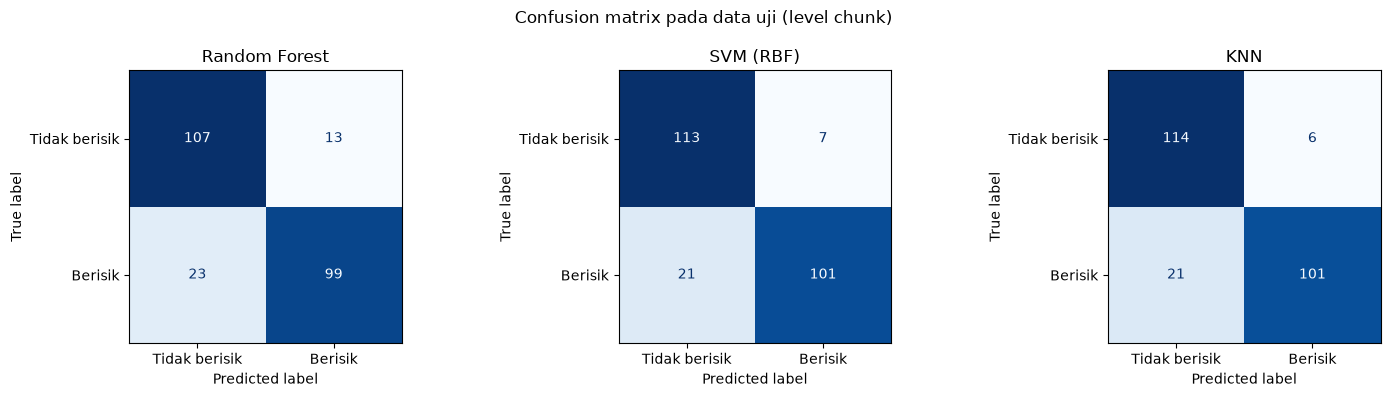

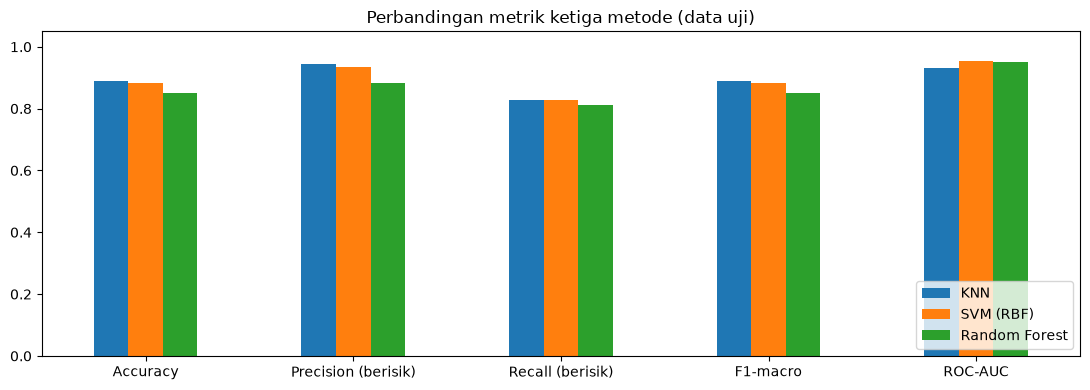

In [14]:
fig, ax = plt.subplots(1, len(prediksi), figsize=(5 * len(prediksi), 4))
for a, (nama, (y_pred, _)) in zip(np.atleast_1d(ax), prediksi.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=[NAMA_LABEL[0], NAMA_LABEL[1]]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(nama)
plt.suptitle("Confusion matrix pada data uji (level chunk)")
plt.tight_layout(); plt.savefig("hasil/04_confusion_matrix.png"); plt.show()

metrik = ["Accuracy", "Precision (berisik)", "Recall (berisik)", "F1-macro", "ROC-AUC"]
df_eval.set_index("Metode")[metrik].T.plot(kind="bar", figsize=(11, 4), rot=0, ylim=(0, 1.05))
plt.title("Perbandingan metrik ketiga metode (data uji)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("hasil/05_perbandingan_metrik.png"); plt.show()

### 5.1 Pemilihan model terbaik
Urutan prioritas: **F1-macro data uji** → F1 level file → F1 cross-validation → waktu prediksi tercepat.
Lalu dicek terhadap kriteria keberhasilan di Business Understanding.

In [15]:
NAMA_TERBAIK = df_eval.loc[0, "Metode"]
model_terbaik = model_terlatih[NAMA_TERBAIK]
baris_terbaik = df_eval.loc[0]
print("MODEL TERBAIK:", NAMA_TERBAIK)
print("Parameter    :", df_tuning.set_index("Metode").loc[NAMA_TERBAIK, "Parameter terbaik"])

kriteria = pd.DataFrame([
    ["F1-macro >= 0.90",            baris_terbaik["F1-macro"],                  baris_terbaik["F1-macro"] >= 0.90],
    ["Precision berisik >= 0.90",   baris_terbaik["Precision (berisik)"],       baris_terbaik["Precision (berisik)"] >= 0.90],
    ["Recall berisik >= 0.85",      baris_terbaik["Recall (berisik)"],          baris_terbaik["Recall (berisik)"] >= 0.85],
    ["Prediksi < 1000 ms / chunk",  baris_terbaik["Waktu prediksi/chunk (ms)"], baris_terbaik["Waktu prediksi/chunk (ms)"] < 1000],
], columns=["Kriteria", "Nilai", "Tercapai"])
kriteria

MODEL TERBAIK: KNN
Parameter    : {'clf__n_neighbors': 5, 'clf__weights': 'uniform'}


,Kriteria,Nilai,Tercapai
0,F1-macro >= 0.90,0.888107,False
1,Precision berisik >= 0.90,0.943925,True
2,Recall berisik >= 0.85,0.827869,False
3,Prediksi < 1000 ms / chunk,17.931786,True


### 5.2 Feature importance (Random Forest)
Seperti disebut di modul, Random Forest dapat menunjukkan fitur mana yang paling berpengaruh.

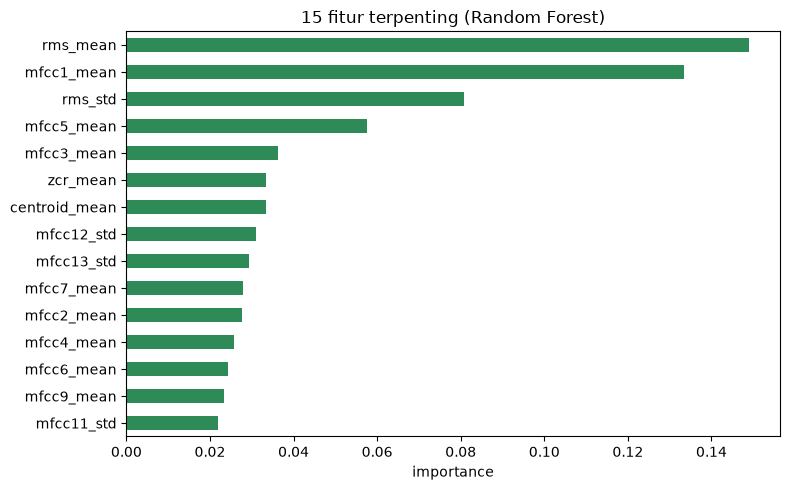

5 fitur paling penting: ['rms_mean', 'mfcc1_mean', 'rms_std', 'mfcc5_mean', 'mfcc3_mean']


In [16]:
rf = model_terlatih["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=fa.NAMA_FITUR).sort_values(ascending=False)
imp.head(15)[::-1].plot(kind="barh", figsize=(8, 5), color="seagreen")
plt.title("15 fitur terpenting (Random Forest)"); plt.xlabel("importance")
plt.tight_layout(); plt.savefig("hasil/06_feature_importance.png"); plt.show()
print("5 fitur paling penting:", list(imp.index[:5]))

### 5.3 Menentukan ambang probabilitas untuk sistem
Model memberi probabilitas "berisik". Ambang default 0,5 tidak selalu cocok untuk lab: teguran
palsu lebih mengganggu daripada terlambat sedikit. Dicari ambang terkecil yang memberi
**precision ≥ 0,90** dengan recall setinggi mungkin. Ambang ini disimpan bersama model.

Ambang probabilitas dipakai sistem: 0.6


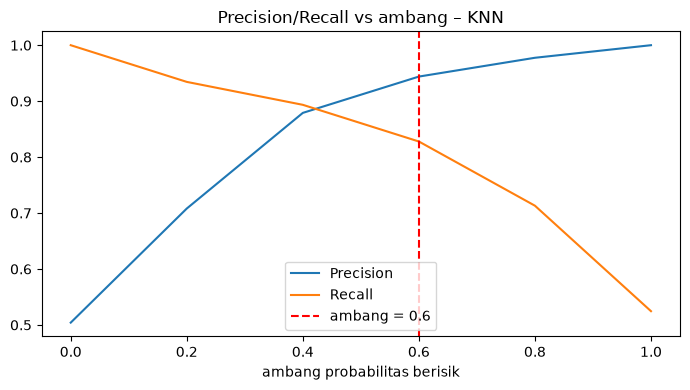

               precision    recall  f1-score   support

Tidak berisik     0.8444    0.9500    0.8941       120
      Berisik     0.9439    0.8279    0.8821       122

     accuracy                         0.8884       242
    macro avg     0.8942    0.8889    0.8881       242
 weighted avg     0.8946    0.8884    0.8881       242



In [17]:
_, prob_terbaik = prediksi[NAMA_TERBAIK]
prec, rec, thr = precision_recall_curve(y_test, prob_terbaik)
kandidat = [(t, p, r) for p, r, t in zip(prec[:-1], rec[:-1], thr) if p >= 0.90 and r >= 0.5]
AMBANG = float(round(max(0.5, kandidat[0][0]), 2)) if kandidat else 0.5
print(f"Ambang probabilitas dipakai sistem: {AMBANG}")

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(AMBANG, color="red", ls="--", label=f"ambang = {AMBANG}")
plt.xlabel("ambang probabilitas berisik"); plt.legend(); plt.title(f"Precision/Recall vs ambang – {NAMA_TERBAIK}")
plt.tight_layout(); plt.savefig("hasil/07_ambang.png"); plt.show()

y_amb = (prob_terbaik >= AMBANG).astype(int)
print(classification_report(y_test, y_amb, target_names=[NAMA_LABEL[0], NAMA_LABEL[1]], digits=4))

**Cara membaca hasil evaluasi:**
- Jika ketiga metode memberi F1 mendekati 1, kemungkinan kedua kelas memang sangat mudah dibedakan
  (misal dari volume). Cek feature importance: jika hanya `rms_mean` yang dominan, model sangat
  bergantung pada volume. Rekam data latih dengan mikrofon yang sama dengan sistem di lab.
- Jika kriteria belum tercapai: aktifkan `AUGMENTASI = True`, tambah data, atau coba durasi chunk 10 detik
  (`DURASI_CHUNK` di `fitur_audio.py`).

---
## 6. Deployment

### 6.1 Melatih ulang model terbaik dengan seluruh data
Evaluasi di atas sudah memberi perkiraan performa yang jujur. Untuk model produksi, metode dan
parameter terbaik dilatih ulang memakai **semua** data (latih + uji) agar model belajar dari sebanyak
mungkin rekaman.

In [18]:
X_semua = np.vstack([X_train, X_test])
y_semua = np.concatenate([y_train, y_test])
model_final = clone(model_terbaik).fit(X_semua, y_semua)

paket = {
    "model": model_final,
    "nama_metode": NAMA_TERBAIK,
    "parameter": df_tuning.set_index("Metode").loc[NAMA_TERBAIK, "Parameter terbaik"],
    "ambang_proba": AMBANG,
    "konfigurasi_fitur": fa.konfigurasi(),
    "nama_label": NAMA_LABEL,
    "metrik_uji": df_eval.loc[0].to_dict(),
    "perbandingan": df_eval.to_dict(orient="records"),
    "dibuat": datetime.now().isoformat(timespec="seconds"),
    "versi": {"python": platform.python_version(), "sklearn": sklearn.__version__,
              "librosa": librosa.__version__},
}
joblib.dump(paket, "model/model_terbaik.joblib")
print("Tersimpan: model/model_terbaik.joblib")
print("Metode:", NAMA_TERBAIK, "| ambang:", AMBANG,
      "| ukuran:", round(os.path.getsize("model/model_terbaik.joblib") / 1024, 1), "KB")

Tersimpan: model/model_terbaik.joblib
Metode: KNN | ambang: 0.6 | ukuran: 167.2 KB


### 6.2 Uji coba: memuat model dan memprediksi file audio

In [19]:
paket_muat = joblib.load("model/model_terbaik.joblib")
assert paket_muat["konfigurasi_fitur"] == fa.konfigurasi(), "Konfigurasi fitur berbeda dengan saat training!"

def prediksi_file(path, paket=paket_muat):
    X = fa.fitur_dari_file(path)
    prob = paket["model"].predict_proba(X)[:, 1]
    return pd.DataFrame({"detik_ke": np.arange(len(prob)) * fa.DURASI_CHUNK,
                         "prob_berisik": prob.round(3),
                         "status": np.where(prob >= paket["ambang_proba"], "BERISIK -> sssttt!", "tenang")})

for folder in KELAS:
    contoh = file_uji[file_uji["kelas"] == folder].iloc[0]
    print(f"\nFile: {contoh['file']}  (label asli: {folder})")
    display(prediksi_file(contoh["path"]).head(6))


File: 24-087 berisik 3.mp3  (label asli: berisik)


,detik_ke,prob_berisik,status
0,0.0,0.8,BERISIK -> sssttt!
1,5.0,0.8,BERISIK -> sssttt!
2,10.0,1.0,BERISIK -> sssttt!
3,15.0,1.0,BERISIK -> sssttt!
4,20.0,1.0,BERISIK -> sssttt!
5,25.0,0.8,BERISIK -> sssttt!



File: 24-081 non-berisik 3.mp3  (label asli: non_berisik)


,detik_ke,prob_berisik,status
0,0.0,0.0,tenang
1,5.0,0.0,tenang
2,10.0,0.0,tenang
3,15.0,0.0,tenang
4,20.0,0.0,tenang
5,25.0,0.0,tenang


### 6.3 Sistem web di lab
Model `model/model_terbaik.joblib` dipakai oleh aplikasi web `app.py` (Flask):

```bash
python app.py          # lalu buka http://localhost:5000 di browser PC lab
```

Arsitektur:
```
Browser (halaman Pantau)                        Server Flask (app.py)
mikrofon --AudioWorklet--> PCM 16-bit/1 detik --> buffer 5 detik per sesi
                                                 -> resample 16 kHz
                                                 -> fitur_audio.ekstrak_fitur (32 fitur, SAMA dgn training)
                                                 -> model.predict_proba
status, grafik, teguran  <------ JSON ---------- -> aturan 3 dari 4 + jeda 30 detik
"sssttt... jangan ramai"                          -> log hasil/log_deteksi.csv
```

Fitur halaman web:
1. **Pantau**: status TENANG/BERISIK, probabilitas, grafik 3 menit, statistik, riwayat teguran, dan
   pengaturan (mikrofon, ambang, aturan konfirmasi, jeda, volume) yang bisa diubah langsung.
2. **Uji File Audio**: unggah MP3/WAV untuk melihat penilaian per potongan 5 detik dan simulasi teguran.
3. **Model**: metode terpilih, parameter, dan tabel perbandingan ketiga metode dari notebook ini.

Saat menegur, browser memutar `suara/peringatan.wav` (jika ada) atau desis + suara sintetis
"jangan ramai", menampilkan layar penuh "sssttt…", dan mengabaikan audio selama teguran diputar
supaya sistem tidak mendeteksi suaranya sendiri.